# 02 · EDA on the cleaned City Hotel data (H2)

**Goal of this notebook:** understand the *cleaned* dataset well enough to make good preprocessing decisions for a **linear regression predicting `ADR`** (average daily rate).

Input: `data/processed/H2_clean_linearreg.csv` (output of `clean_data_merge.ipynb`).
Nothing here modifies the data; every decision is written down in the last section and implemented in `03_linreg_preprocessing.ipynb`.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60, "display.width", 140)

# Find data/processed/H2_clean.csv from the current folder or any parent folder
CLEAN_PATH = next(p / "data" / "processed" / "H2_clean_linearreg.csv"
                  for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "data" / "processed" / "H2_clean_linearreg.csv").exists())

# IMPORTANT: keep_default_na=False. Your cleaning step writes the string "None" for
# missing Agent/Company; pandas would otherwise silently read it back as NaN.
df = pd.read_csv(CLEAN_PATH, keep_default_na=False, na_values=[""], parse_dates=["arrival_date"])
print(CLEAN_PATH, df.shape)
print("NaN cells:", int(df.isna().sum().sum()))

d:\fall 2027\ML\City-Hotel-Booking\data\processed\H2_clean_linearreg.csv (78890, 47)
NaN cells: 0


## 1 · Structure and sanity checks

In [2]:
num_cols = df.select_dtypes("number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.drop("arrival_date").tolist()
print(f"{len(num_cols)} numeric, {len(cat_cols)} categorical, 1 datetime")
print("Duplicate rows :", df.duplicated().sum())
print("Date range     :", df.arrival_date.min().date(), "->", df.arrival_date.max().date())
print("Max ADR        :", df.ADR.max(), "| min ADR:", df.ADR.min())
df[cat_cols].nunique().sort_values(ascending=False).to_frame("n_unique").T

33 numeric, 13 categorical, 1 datetime
Duplicate rows : 25856
Date range     : 2015-07-01 -> 2017-08-31
Max ADR        : 510.0 | min ADR: 0.0


,ReservationStatusDate,Agent,Company,Country,ArrivalDateMonth,MarketSegment,AssignedRoomType,ReservedRoomType,DistributionChannel,Meal,CustomerType,DepositType,ReservationStatus
n_unique,864,224,204,167,12,8,8,7,5,4,4,3,3


## 2 · The target: `ADR`
Three things matter for linear regression: **zeros**, **skew**, and **the upper tail**.

In [3]:
adr = df.ADR
print(adr.describe(percentiles=[.01,.05,.5,.95,.99]).round(2).to_string())
zeros = df[df.ADR == 0]
print(f"\nADR == 0 : {len(zeros)} rows ({len(zeros)/len(df):.2%})")
print("\nADR == 0 by MarketSegment:")
print(zeros.MarketSegment.value_counts().to_frame("rows").assign(share=lambda t: (t.rows/t.rows.sum()).round(3)))
print(f"\nSkew  all ADR: {adr.skew():.2f} | ADR>0: {adr[adr>0].skew():.2f} | log(ADR>0): {np.log(adr[adr>0]).skew():.2f} | sqrt(ADR>0): {np.sqrt(adr[adr>0]).skew():.2f}")

count    78890.00
mean       105.79
std         38.70
min          0.00
1%           0.00
5%          62.00
50%        100.00
95%        175.50
99%        228.00
max        510.00

ADR == 0 : 805 rows (1.02%)

ADR == 0 by MarketSegment:
               rows  share
MarketSegment             
Complementary   480  0.596
Offline TA/TO   134  0.166
Groups          125  0.155
Direct           37  0.046
Online TA        22  0.027
Corporate         7  0.009

Skew  all ADR: 0.92 | ADR>0: 1.18 | log(ADR>0): -1.14 | sqrt(ADR>0): 0.47


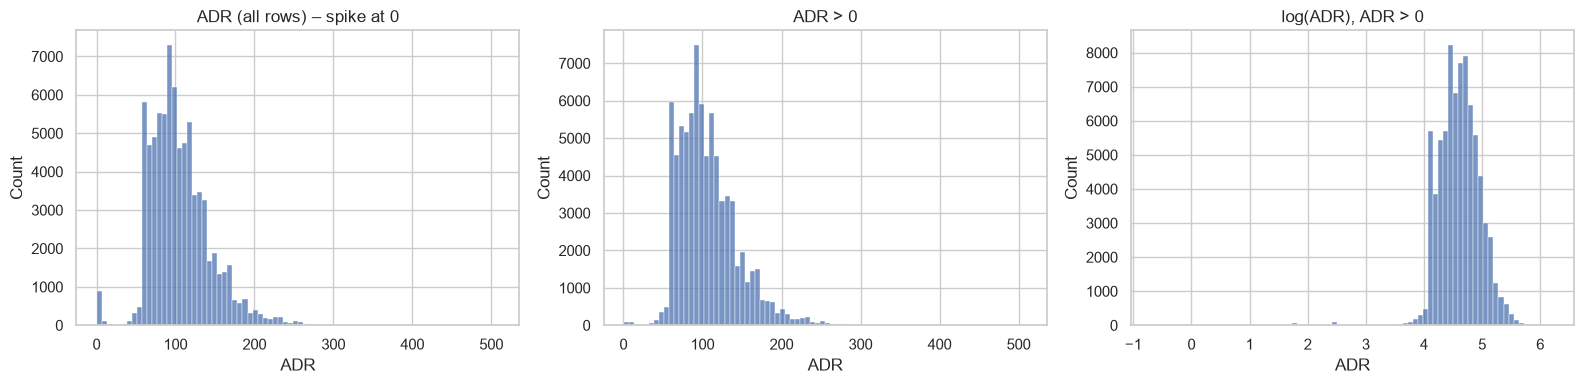

In [4]:
pos = df[df.ADR > 0]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df.ADR, bins=80, ax=ax[0]); ax[0].set_title("ADR (all rows) – spike at 0")
sns.histplot(pos.ADR, bins=80, ax=ax[1]); ax[1].set_title("ADR > 0")
sns.histplot(np.log(pos.ADR), bins=80, ax=ax[2]); ax[2].set_title("log(ADR), ADR > 0")
plt.tight_layout(); plt.show()

**Why this matters.** A zero ADR is not a price – it is a free/complimentary stay (mostly `Complementary` segment). (see §8).

## 3 · Numeric features: distributions and outliers

In [5]:
num_feats = ["LeadTime","total_nights","Adults","Children","Babies","BookingChanges",
             "DaysInWaitingList","PreviousCancellations","PreviousBookingsNotCanceled",
             "TotalOfSpecialRequests","RequiredCarParkingSpaces","waiting_lead_ratio"]
summ = df[num_feats].describe(percentiles=[.5,.99]).T[["mean","50%","99%","max"]]
summ["skew"] = df[num_feats].skew()
summ["%zero"] = (df[num_feats] == 0).mean() * 100
summ.round(2).sort_values("skew", ascending=False)

,mean,50%,99%,max,skew,%zero
Babies,0.00,0.0,0.00,10.00,44.95,99.54
PreviousBookingsNotCanceled,0.13,0.0,3.00,72.00,23.08,98.01
PreviousCancellations,0.08,0.0,1.00,21.00,16.56,93.18
DaysInWaitingList,3.24,0.0,93.00,391.00,10.28,95.64
BookingChanges,0.18,0.0,2.00,18.00,6.37,87.18
waiting_lead_ratio,0.02,0.0,0.62,0.98,6.37,95.64
RequiredCarParkingSpaces,0.02,0.0,1.00,3.00,6.30,97.57
Children,0.09,0.0,2.00,3.00,4.33,93.55
total_nights,2.98,3.0,9.00,48.00,3.42,0.00
TotalOfSpecialRequests,0.55,0.0,3.00,5.00,1.40,60.45


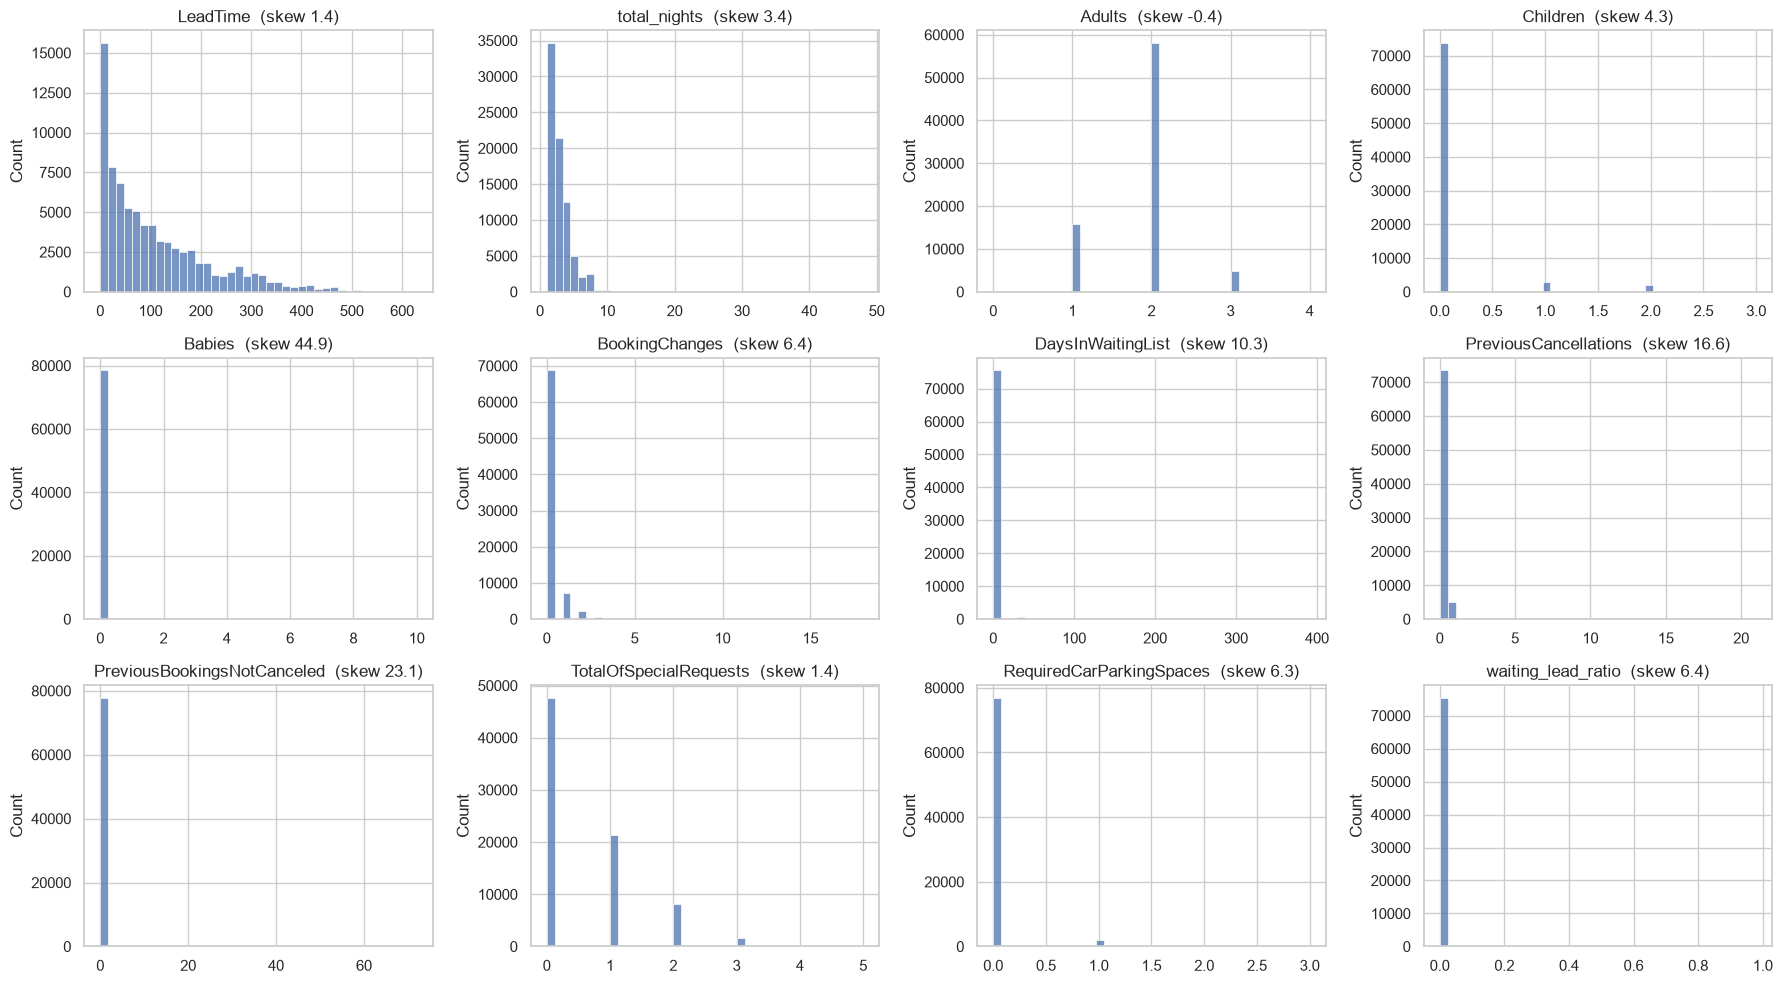

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for a, c in zip(axes.ravel(), num_feats):
    sns.histplot(df[c], bins=40, ax=a); a.set_title(f"{c}  (skew {df[c].skew():.1f})"); a.set_xlabel("")
plt.tight_layout(); plt.show()

In [7]:
print("Babies value counts :", df.Babies.value_counts().to_dict())
print("Adults value counts :", df.Adults.value_counts().to_dict())
print("total_guests >= 6   :", (df.total_guests >= 6).sum(), "rows")
print("total_nights > 14   :", (df.total_nights > 14).sum(), "rows | max", df.total_nights.max())
print("LeadTime > 365      :", (df.LeadTime > 365).sum(), "rows | max", df.LeadTime.max())

Babies value counts : {0: 78524, 1: 358, 2: 6, 10: 1, 9: 1}
Adults value counts : {2: 58089, 1: 15786, 3: 4769, 0: 215, 4: 31}
total_guests >= 6   : 2 rows
total_nights > 14   : 152 rows | max 48
LeadTime > 365      : 2703 rows | max 629


Counts like `PreviousCancellations`, `DaysInWaitingList`, `BookingChanges` are >85% zeros with a very long tail (skew 5–23): they behave like flags, and the raw counts would be dominated by a handful of rows. `LeadTime` and `total_nights` are moderately/strongly right-skewed and suit a log transform.

## 4 · Categorical features: levels and how ADR differs between them

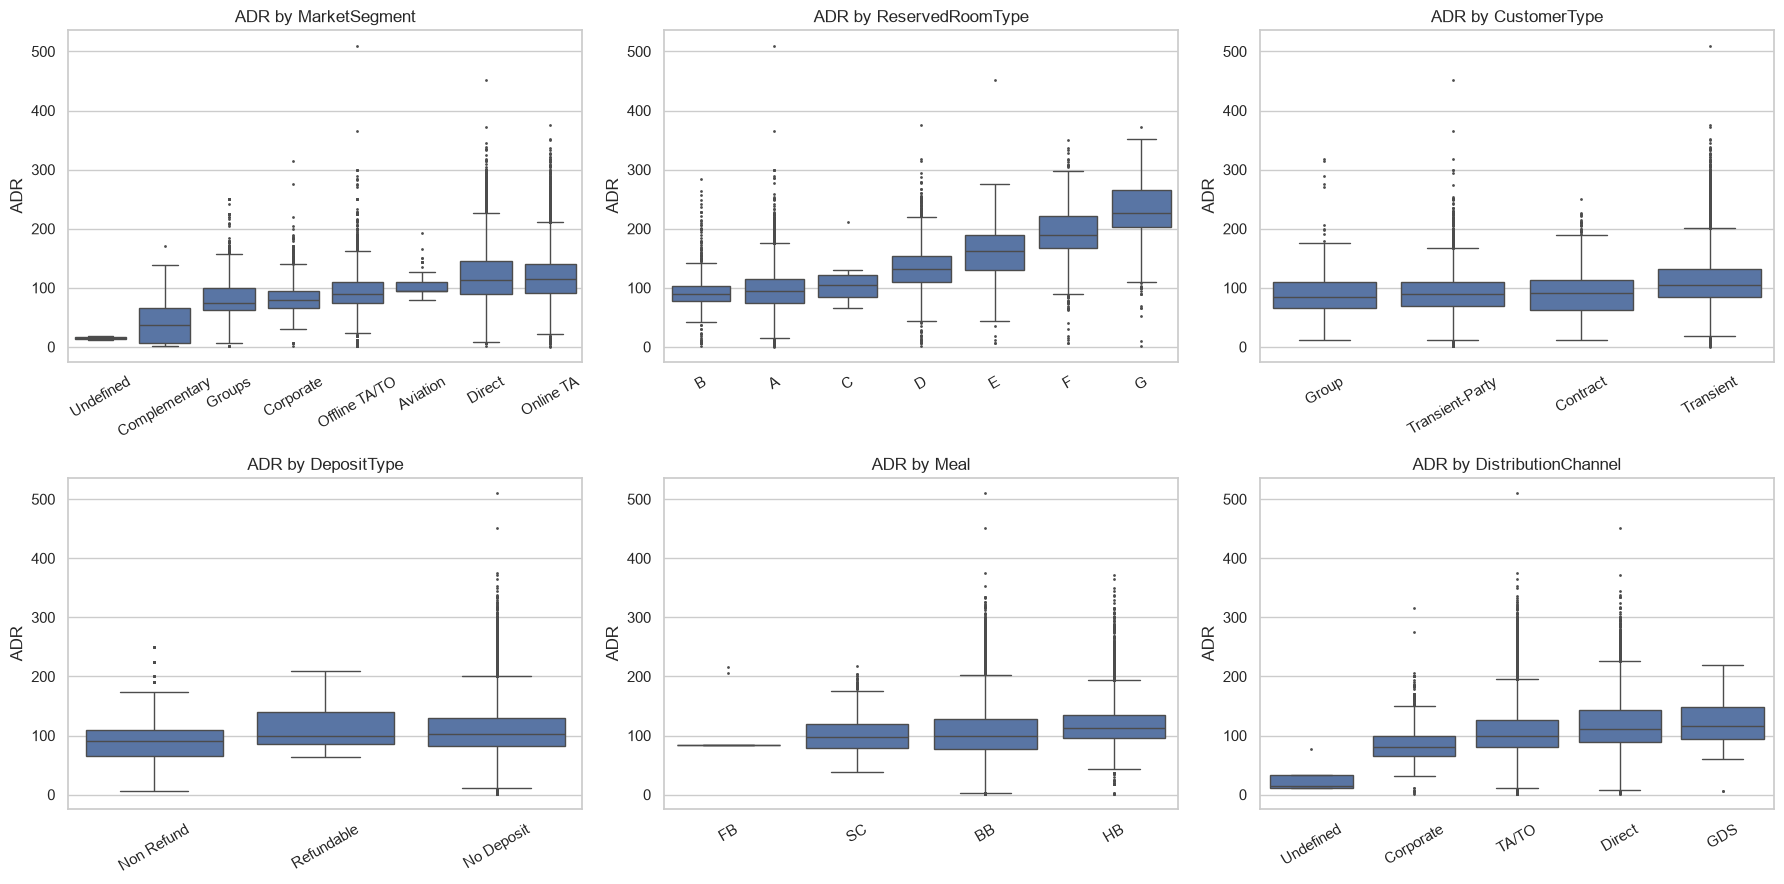

In [8]:
cats = ["MarketSegment","ReservedRoomType","CustomerType","DepositType","Meal","DistributionChannel"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for a, c in zip(axes.ravel(), cats):
    order = pos.groupby(c).ADR.median().sort_values().index
    sns.boxplot(data=pos, x=c, y="ADR", order=order, ax=a, fliersize=1)
    a.set_title(f"ADR by {c}"); a.tick_params(axis="x", rotation=30); a.set_xlabel("")
plt.tight_layout(); plt.show()

In [9]:
for c in ["Meal","DistributionChannel","MarketSegment","ReservedRoomType","DepositType","CustomerType"]:
    vc = df[c].value_counts()
    print(f"{c:<20}", vc.to_dict())

Meal                 {'BB': 62043, 'SC': 10429, 'HB': 6374, 'FB': 44}
DistributionChannel  {'TA/TO': 68656, 'Direct': 6675, 'Corporate': 3365, 'GDS': 190, 'Undefined': 4}
MarketSegment        {'Online TA': 38572, 'Offline TA/TO': 16642, 'Groups': 13955, 'Direct': 6014, 'Corporate': 2961, 'Complementary': 513, 'Aviation': 231, 'Undefined': 2}
ReservedRoomType     {'A': 62262, 'D': 11719, 'F': 1782, 'E': 1529, 'B': 1107, 'G': 478, 'C': 13}
DepositType          {'No Deposit': 66003, 'Non Refund': 12867, 'Refundable': 20}
CustomerType         {'Transient': 59031, 'Transient-Party': 17281, 'Contract': 2288, 'Group': 290}


**Rare levels** (e.g. Meal `FB` = 44 rows, MarketSegment `Undefined` = 2, room type `C` = 13, DepositType `Refundable` = 20)

### High-cardinality columns: `Country`, `Agent`, `Company`

C:\Users\menna emad\AppData\Local\Temp\ipykernel_22284\2356467790.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(); plt.show()


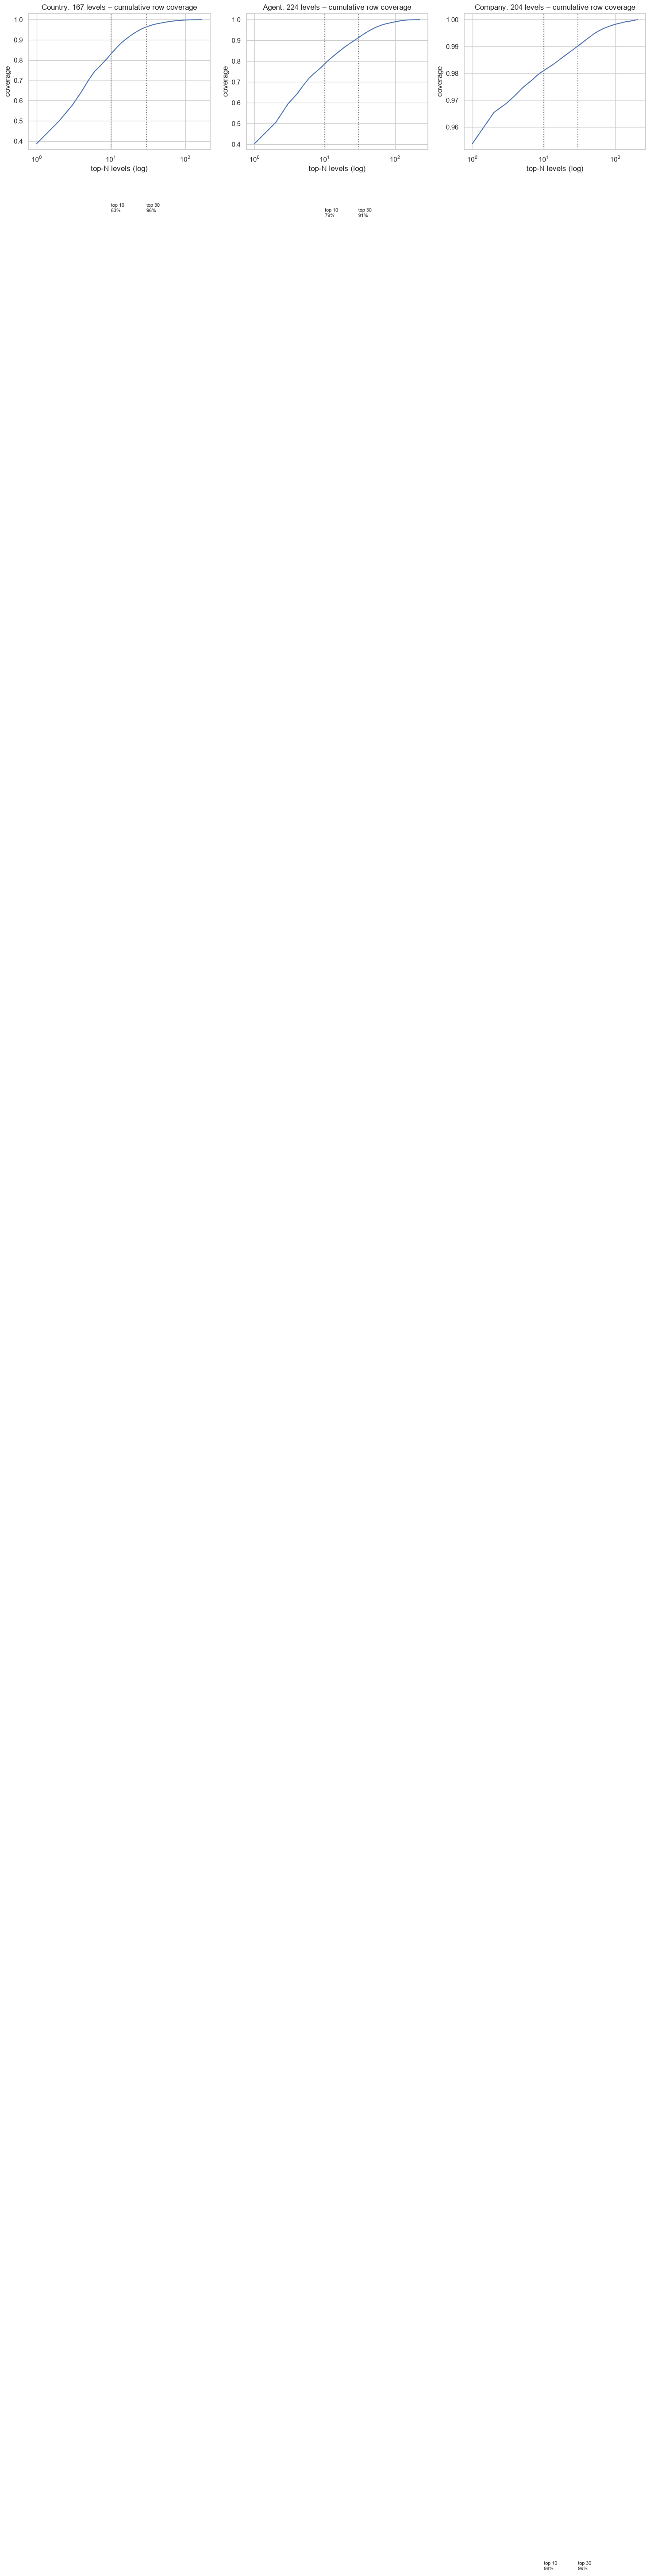

Country  levels=167 | levels with >=100 rows: 35 | rows in levels <100: 2.7%
Agent    levels=224 | levels with >=100 rows: 53 | rows in levels <100: 3.7%
Company  levels=204 | levels with >=100 rows:  8 | rows in levels <100: 2.1%


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for a, c in zip(axes, ["Country","Agent","Company"]):
    vc = df[c].value_counts()
    cum = vc.cumsum() / vc.sum()
    a.plot(range(1, len(cum)+1), cum.values); a.set_xscale("log")
    a.set_title(f"{c}: {len(vc)} levels – cumulative row coverage"); a.set_xlabel("top-N levels (log)"); a.set_ylabel("coverage")
    for n in (10, 30):
        if n <= len(cum): a.axvline(n, ls=":", c="grey"); a.text(n, 0.05, f"top {n}\n{cum.iloc[n-1]:.0%}", fontsize=8)
plt.tight_layout(); plt.show()

for c in ["Country","Agent","Company"]:
    vc = df[c].value_counts()
    print(f"{c:<8} levels={len(vc):>3} | levels with >=100 rows: {(vc>=100).sum():>2} | rows in levels <100: {vc[vc<100].sum()/len(df):.1%}")

## 5 · Time: seasonality and trend

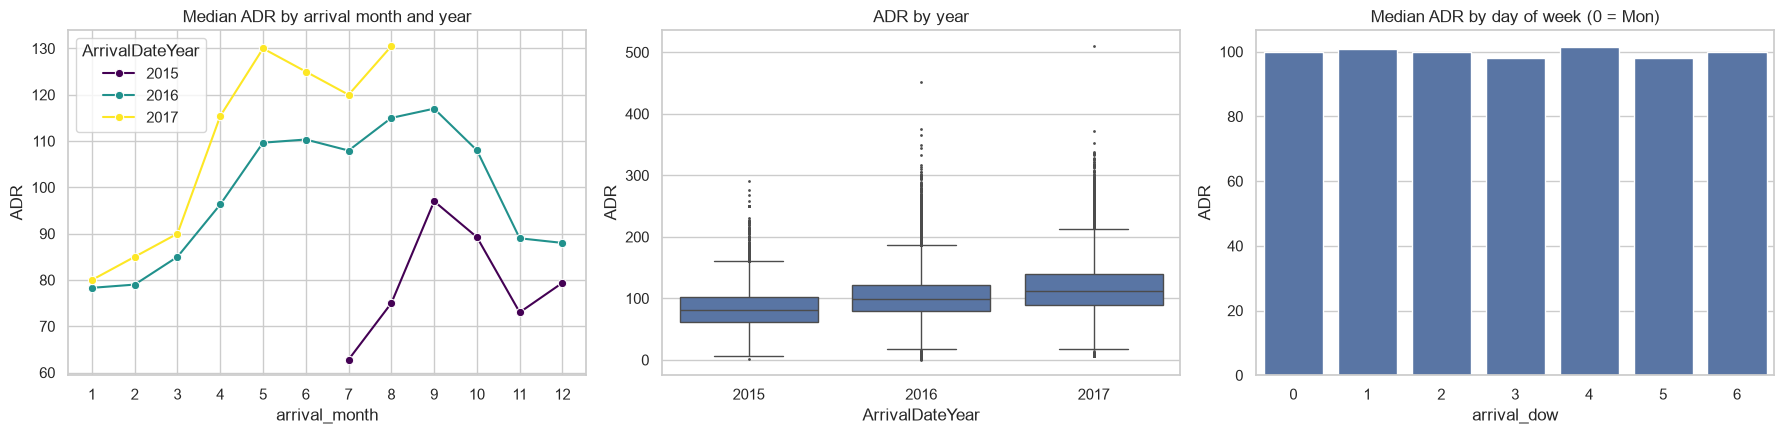

                       min        max  count
ArrivalDateYear                             
2015            2015-07-01 2015-12-31  13610
2016            2016-01-01 2016-12-31  37887
2017            2017-01-01 2017-08-31  27393


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
m = pos.groupby(["ArrivalDateYear","arrival_month"]).ADR.median().reset_index()
sns.lineplot(data=m, x="arrival_month", y="ADR", hue="ArrivalDateYear", marker="o", palette="viridis", ax=ax[0])
ax[0].set_title("Median ADR by arrival month and year"); ax[0].set_xticks(range(1,13))
sns.boxplot(data=pos, x="ArrivalDateYear", y="ADR", ax=ax[1], fliersize=1); ax[1].set_title("ADR by year")
sns.barplot(data=pos, x="arrival_dow", y="ADR", estimator="median", errorbar=None, ax=ax[2]); ax[2].set_title("Median ADR by day of week (0 = Mon)")
plt.tight_layout(); plt.show()
print(df.groupby("ArrivalDateYear").arrival_date.agg(["min","max","count"]))

ADR has **both** a strong seasonal cycle (summer high, Nov–Mar low) and an **upward trend across years**. Year is only partly observed (2015 = Jul–Dec, 2017 = Jan–Aug), so month and year are not independent. 

## 6 · Guests, stay length and lead time vs ADR

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
g = pos[pos.total_guests <= 5]
sns.boxplot(data=g, x="total_guests", y="ADR", ax=ax[0], fliersize=1); ax[0].set_title("ADR by total_guests (<=5)")
sns.boxplot(data=pos[pos.total_nights<=14], x="total_nights", y="ADR", ax=ax[1], fliersize=1); ax[1].set_title("ADR by total_nights (<=14)")
bins = pd.qcut(pos.LeadTime, 10, duplicates="drop")
sns.barplot(x=bins.astype(str), y=pos.ADR, estimator="median", errorbar=None, ax=ax[2]); ax[2].set_title("Median ADR by LeadTime decile"); ax[2].tick_params(axis="x", rotation=60); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

## 7 · Correlations and multicollinearity

In [ ]:
corr_cols = [c for c in df.select_dtypes("number").columns if c not in ("ArrivalDateDayOfMonth",)]
corr = pos[corr_cols].corr()
print("Correlation with ADR (ADR>0):")
print(corr["ADR"].drop("ADR").sort_values(key=abs, ascending=False).round(3).head(15).to_string())

Correlation with ADR (ADR>0):
total_guests                  0.431
Children                      0.366
has_children                  0.323
ArrivalDateYear               0.279
Adults                        0.265
TotalOfSpecialRequests        0.215
has_history                  -0.211
has_previous_cancellations   -0.199
LeadTime                     -0.193
PreviousCancellations        -0.147
has_company                  -0.118
IsRepeatedGuest              -0.105
has_waiting_list             -0.091
has_past_stays               -0.089
waiting_lead_ratio           -0.084


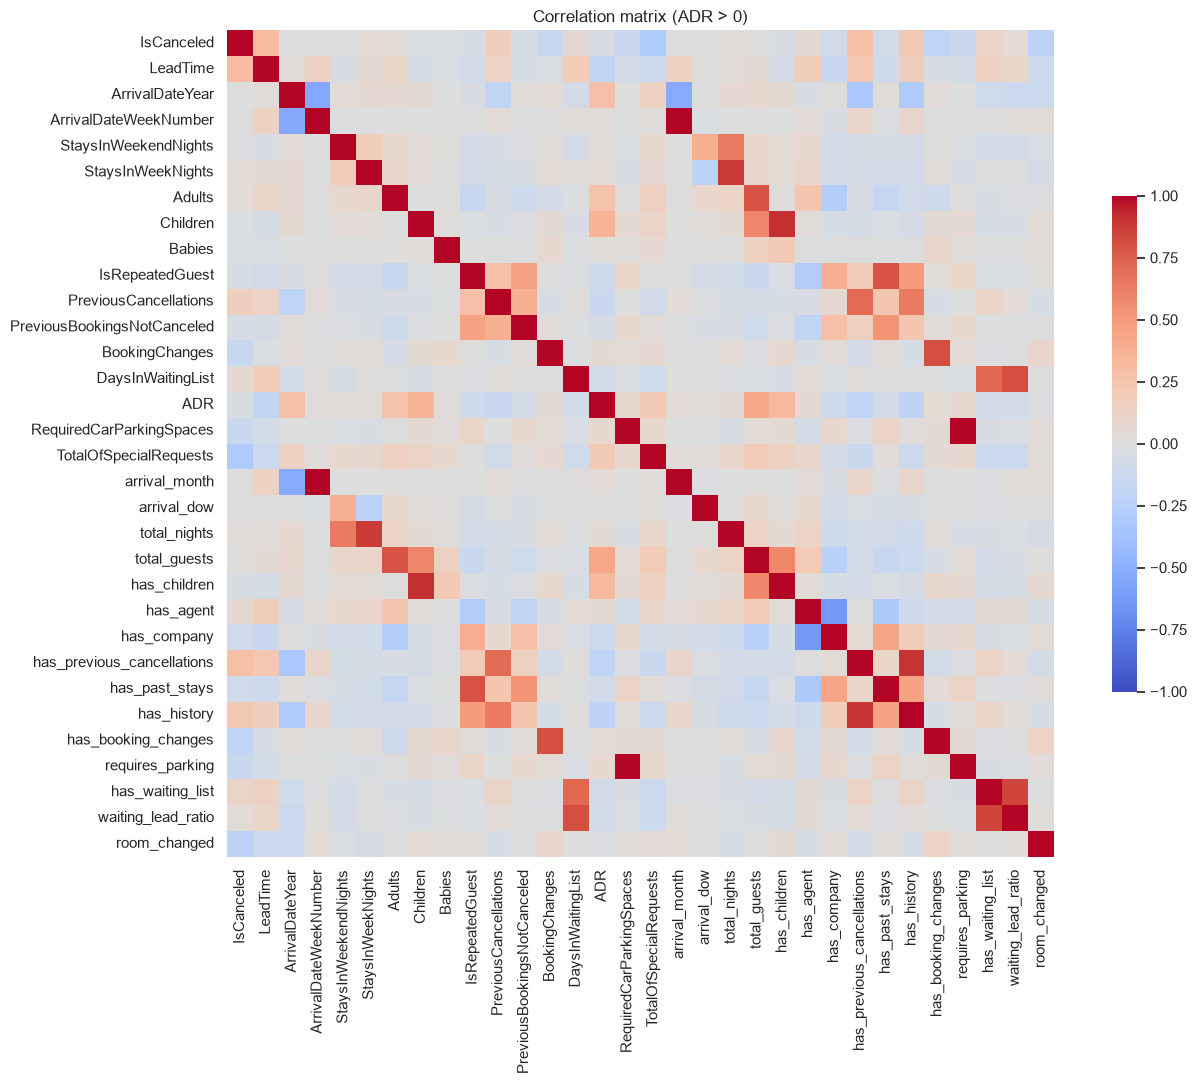

In [ ]:
plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .6},
            xticklabels=True, yticklabels=True)
plt.title("Correlation matrix (ADR > 0)"); plt.tight_layout(); plt.show()

In [ ]:
# Pairs of numeric features that carry (almost) the same information
c = corr.abs().where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(ascending=False)
c[c > 0.7].round(3).to_frame("|r|")

,,|r|
RequiredCarParkingSpaces,requires_parking,0.997
ArrivalDateWeekNumber,arrival_month,0.995
Children,has_children,0.909
has_previous_cancellations,has_history,0.903
StaysInWeekNights,total_nights,0.880
has_waiting_list,waiting_lead_ratio,0.851
BookingChanges,has_booking_changes,0.816
DaysInWaitingList,waiting_lead_ratio,0.815
IsRepeatedGuest,has_past_stays,0.805
Adults,total_guests,0.792


Several columns are **exact or near-exact combinations** of each other (`total_guests = Adults+Children+Babies`, `total_nights = weekend+week nights`, the `has_*` flags vs their raw counts, `IsRepeatedGuest` vs `has_history`). Putting all of them in an OLS model makes coefficients unstable/uninterpretable (and `total_guests` + its three parts is perfectly collinear).

| # | Finding | Decision  |
|---|---|---|
| 1 | 805 rows (1.02%) have `ADR = 0`; 480 are `Complementary` (93.57% of that segment's 513 bookings) | **Keep all 480 `Complementary` rows** to preserve their distinct pricing pattern through `MarketSegment` encoding. **Drop the remaining 325 non-Complementary `ADR = 0` rows** as isolated cases that cannot be reliably distinguished from standard paid bookings using available features. |
| 2 | ADR>0 is right-skewed (skew ≈ 1.1) with a tail up to 510; `log` over-corrects (skew ≈ −1.55), `sqrt` lands near 0.35 | Compare **raw vs log vs sqrt target**; judge by residual plots and error in ADR units, not skew alone |
| 3 | `ReservationStatus`, `ReservationStatusDate` are outcomes known only after the stay | **Drop (target leakage)**; also review `IsCanceled`, `AssignedRoomType`, `room_changed`, `BookingChanges` as post-booking info |
| 4 | Strong seasonality + year trend | One-hot `arrival_month`, keep `ArrivalDateYear` numeric; drop `ArrivalDateWeekNumber` / day-of-month (weak correlation) |
| 5 | Redundant/derived columns (`total_guests`, weekend/week nights, `has_*` vs counts) | Keep one representation of each concept; verify with **VIF** |
| 6 | Heavy-tailed counts (`LeadTime`, `total_nights`, waiting list, previous cancellations) | `log1p` for LeadTime/total_nights; use flags for the rare-event counts |
| 7 | `Country` (167), `Agent` (224), `Company` (204) levels | Group rare levels (<100 rows) into one 'infrequent' level; `Company` → just `has_company` |
| 8| Rare levels in `Meal`, `MarketSegment`, `ReservedRoomType`, `DepositType` | Same rare-level pooling |
| 9 | Linear regression is scale-sensitive | `StandardScaler` on numerics, **fit on train only** |